# Functional Boxplot (curve ensembles)

**Family:** Uncertainty &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Advanced

> *Uncertainty:* Show what is not known (intervals, probabilities and possible outcomes) so readers do not over-trust a single number.

## Design purpose

A boxplot for whole curves. Every path in an ensemble (simulations, scenarios, yield curves) is ranked by band depth, a measure of how central it is as a shape. The chart draws the most central curve (median), the envelope of the 50% most central curves, whisker envelopes, and the outlier curves that leave them. Unlike a pointwise mean ± 2 SD band, it is built from whole real paths, follows the skew of the ensemble, and flags individual scenarios worth a closer look.

## When to use

- Summarise hundreds of Monte Carlo paths, scenarios or forecast ensembles without spaghetti
- Flag the individual scenarios that run far outside the typical range
- Compare the typical path with its spread when the distribution is skewed (wealth, prices)

## Avoid when

- Only a few curves (draw them all)
- The reader needs probabilities at a specific horizon (show a fan chart or the distribution at that date)
- Curves are on different time grids (align or interpolate them first)

## Alternatives

- Fan chart (pointwise quantiles)
- Spaghetti with highlight
- Line-density image (datashader_timeseries)

## Design tips

- What it fixes: mean ± 2 SD bands assume symmetry, can extend to impossible values, and say nothing about which paths are unusual
- Use modified band depth (MBD) for many crossing curves; statsmodels provides `banddepth` and `fboxplot`
- The 50% central region is built from whole curves, so it is usually wider than the pointwise interquartile range (it is conservative)
- Show outlier curves individually; they are often the most interesting scenarios
- The whisker rule catches magnitude outliers; add a shape-outlier method (e.g. outlyingness on derivatives) when unusual shapes matter

## Example

300 simulated 10-year paths of a $100 portfolio (monthly steps, log-normal returns, about 7% a year with 15% volatility).

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from statsmodels.graphics.functional import banddepth

### Data

In [2]:
rng = np.random.default_rng(2011)
n_paths, months = 300, 120
log_r = rng.normal(0.006, 0.042, (n_paths, months))
paths = 100 * np.exp(np.cumsum(log_r, axis=1))
paths = np.hstack([np.full((n_paths, 1), 100.0), paths])
t = np.arange(months + 1) / 12
depth = banddepth(paths, method="MBD")
pd.Series(depth).describe().round(3)

count    300.000
mean       0.338
std        0.102
min        0.073
25%        0.268
50%        0.362
75%        0.421
max        0.482
dtype: float64

### Plot

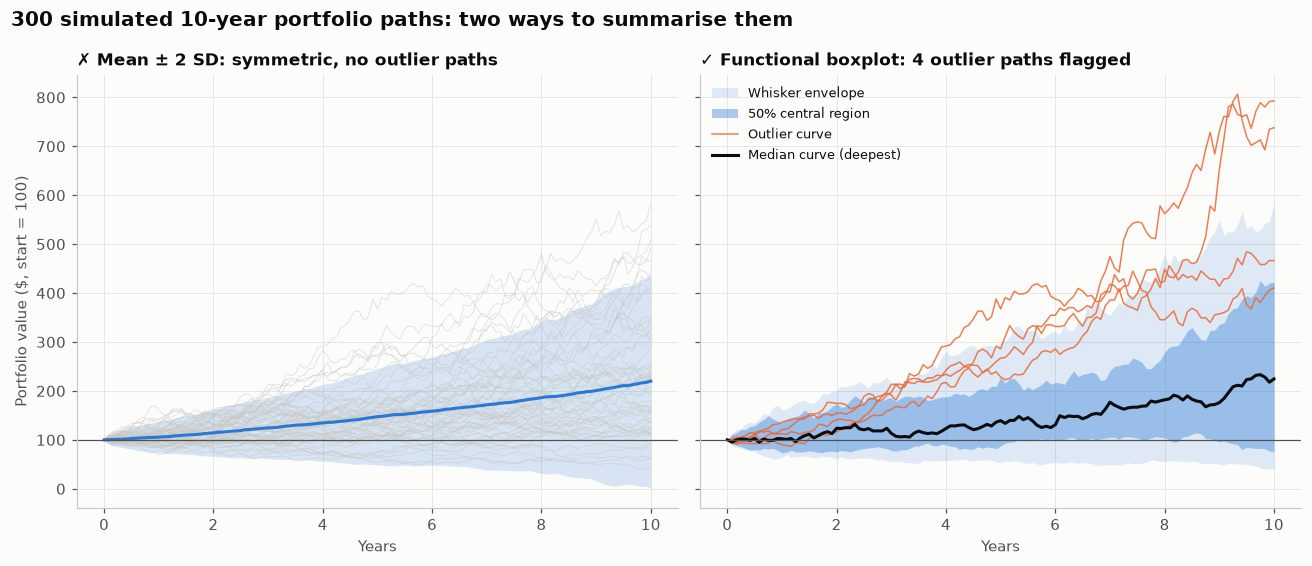

In [3]:
rank = np.argsort(-depth)                    # most central first
median = paths[rank[0]]
central = paths[rank[: n_paths // 2]]        # the 50% deepest curves
c_lo, c_hi = central.min(0), central.max(0)
w_lo, w_hi = c_lo - 1.5 * (c_hi - c_lo), c_hi + 1.5 * (c_hi - c_lo)
outlier = ((paths < w_lo) | (paths > w_hi)).any(1)
w_lo = np.maximum(w_lo, paths[~outlier].min(0))  # whiskers end at the most extreme non-outlier curve
w_hi = np.minimum(w_hi, paths[~outlier].max(0))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 5.2), sharey=True)
m, s = paths.mean(0), paths.std(0)
a1.plot(t, paths[:60].T, color="#c9c8c3", linewidth=0.5, alpha=0.6)
a1.fill_between(t, m - 2 * s, m + 2 * s, color=PALETTE[0], alpha=0.18, linewidth=0)
a1.plot(t, m, color=PALETTE[0])
a1.set_title("✗ Mean ± 2 SD: symmetric, no outlier paths", fontsize=11)
a1.set_ylabel("Portfolio value ($, start = 100)")

a2.fill_between(t, w_lo, w_hi, color=PALETTE[0], alpha=0.14, linewidth=0, label="Whisker envelope")
a2.fill_between(t, c_lo, c_hi, color=PALETTE[0], alpha=0.38, linewidth=0, label="50% central region")
for k, i in enumerate(np.where(outlier)[0]):
    a2.plot(t, paths[i], color=PALETTE[1], linewidth=1, alpha=0.85, label="Outlier curve" if k == 0 else None)
a2.plot(t, median, color="#0b0b0b", linewidth=2, label="Median curve (deepest)")
a2.set_title(f"✓ Functional boxplot: {outlier.sum()} outlier paths flagged", fontsize=11)
a2.legend(loc="upper left", fontsize=8.5)
for ax in (a1, a2):
    ax.set_xlabel("Years")
    ax.axhline(100, color="#52514e", linewidth=0.8)

fig.suptitle(f"{n_paths} simulated 10-year portfolio paths: two ways to summarise them", x=0.01,
             ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
plt.show()

## How to read it

The left panel's symmetric band treats a fall towards zero as being as likely as a large gain, and no line in it is a path any portfolio actually followed. On the right, the black line is the most central real path and the dark band the 50% most central paths. Both are skewed upward, as wealth paths are. The orange curves leave the whisker envelope; they are the scenarios to inspect individually. This rule flags extreme magnitudes. Paths with an unusual shape but ordinary values (a crash and recovery) need a separate shape-outlier check.

## Reference

This method comes from the research literature:

- Sun, Y. & Genton, M. G. (2011). Functional boxplots. Journal of Computational and Graphical Statistics 20(2), 316–334. <https://doi.org/10.1198/jcgs.2011.09224>
- Mirzargar, M., Whitaker, R. T. & Kirby, R. M. (2014). Curve boxplot: generalization of boxplot for ensembles of curves. IEEE Transactions on Visualization and Computer Graphics 20(12), 2654–2663. <https://doi.org/10.1109/TVCG.2014.2346455>

---
Standalone script: [`functional_boxplot.py`](functional_boxplot.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)